# Bubble Scaled by Radius vs. by Area

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

Readers judge a circle by its area. If the radius (or diameter) is made proportional to the value, the area grows with the square of the value, so a value twice as large looks four times as large and an 8× difference looks like a 64× difference.

## When to use

- Scale bubble AREA proportional to value (radius ∝ √value) in bubble charts, bubble maps and packed circles
- Use bars instead when precise comparison matters, since people underestimate area differences even when area is scaled correctly

## Avoid when

- Hand-built bubble charts that set radius or diameter from the value
- Icons or pictograms scaled in both width and height by the value

## Alternatives

- Bar chart (precise comparison)
- Area-scaled bubbles with a size legend
- Pictogram / isotype (count icons instead of scaling one)

## Design tips

- In matplotlib `scatter`, `s` is already an area (pt²), so pass s ∝ value, not s ∝ value²
- In plotly, use `sizemode="area"`
- Add a size legend with 2–3 reference bubbles

## Example

Annual patient volume of four clinics (1k, 2k, 4k and 8k).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
df = pd.DataFrame({"clinic": ["Clinic A", "Clinic B", "Clinic C", "Clinic D"],
                   "patients_k": [1, 2, 4, 8]})
df

,clinic,patients_k
0,Clinic A,1
1,Clinic B,2
2,Clinic C,4
3,Clinic D,8


### Plot

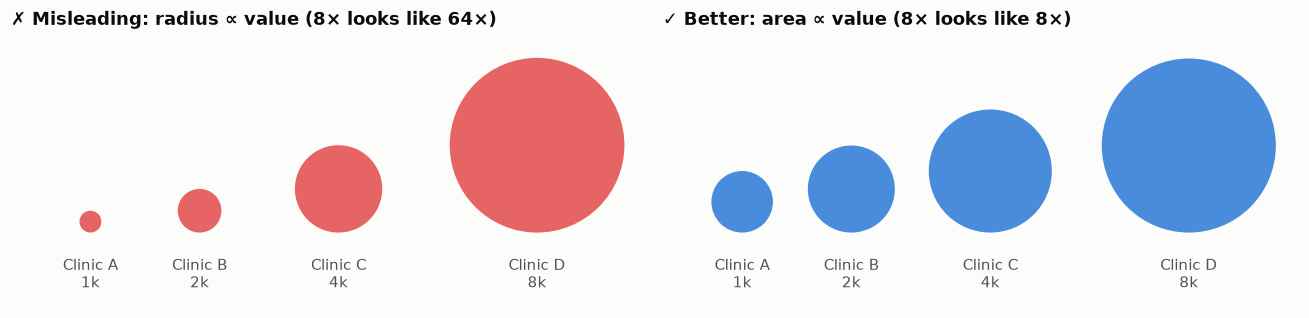

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
xs = np.array([0.5, 1.6, 3.0, 5.0])
for ax, mode in [(ax1, "radius"), (ax2, "area")]:
    v = df["patients_k"].to_numpy()
    radius = 0.11 * v if mode == "radius" else 0.31 * np.sqrt(v)   # data units
    for x, r, name, val in zip(xs, radius, df["clinic"], v):
        ax.add_patch(plt.Circle((x, r), r, color=PALETTE[0] if mode == "area" else PALETTE[7],
                                alpha=0.85, linewidth=0))
        ax.text(x, -0.25, f"{name}\n{val}k", ha="center", va="top", fontsize=9.5, color="#52514e")
    ax.set_xlim(-0.3, 6.1)
    ax.set_ylim(-0.75, 2.0)
    ax.set_aspect("equal")
    ax.axis("off")
ax1.set_title("✗ Misleading: radius ∝ value (8× looks like 64×)", fontsize=11.5)
ax2.set_title("✓ Better: area ∝ value (8× looks like 8×)", fontsize=11.5)
fig.tight_layout()
plt.show()

## How to read it

Clinic D sees 8× as many patients as Clinic A. On the left its circle covers 64× the area and dominates the panel. On the right it covers 8× the area, which matches the data.

---
Standalone script: [`bubble_radius_scaling.py`](bubble_radius_scaling.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)